# 04 — Modélisation & soumission

**Rôle de ce notebook** : entraîner et valider un modèle de prévision du tonnage en simulant la
tâche réelle (extrapoler vers une campagne future jamais vue), puis produire `submission.csv`.

- Validation temporelle (train sur les campagnes passées, validation sur la dernière) et
  GroupKFold par parcelle.
- Baseline « rendement N-1 » (méthode empirique citée par le guide).
- Modèle LightGBM sur la cible `log1p(Tonnage)`.

In [1]:

import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
import lightgbm as lgb

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

DATA_DIR = Path(r"C:\Github_Projects\Competition_Kaggle\Kaggle_competition\Data")
OUT_DIR = DATA_DIR / "processed"
PROJECT_ROOT = Path(r"C:\Github_Projects\Competition_Kaggle\Kaggle_competition")

X_train = pd.read_csv(OUT_DIR / "X_train.csv")
X_test = pd.read_csv(OUT_DIR / "X_test.csv")
y_train = pd.read_csv(OUT_DIR / "y_train.csv").iloc[:, 0]
meta_train = pd.read_csv(OUT_DIR / "meta_train.csv")
meta_test = pd.read_csv(OUT_DIR / "meta_test.csv")

print(X_train.shape, X_test.shape, y_train.shape)


(1629, 44) (411, 44) (1629,)


## 1. Validation temporelle : train = 20/21→22/23, validation = 23/24

On simule l'extrapolation vers une campagne future, exactement la tâche demandée par la compétition (test = 24/25, jamais vue en train).

In [2]:

campagnes = meta_train["Campagne"]
is_valid_time = campagnes == "23/24"

X_tr_time, X_val_time = X_train[~is_valid_time], X_train[is_valid_time]
y_tr_time, y_val_time = y_train[~is_valid_time], y_train[is_valid_time]

print(f"Train (20/21-22/23): {X_tr_time.shape[0]} lignes | Validation (23/24): {X_val_time.shape[0]} lignes")


Train (20/21-22/23): 1238 lignes | Validation (23/24): 391 lignes


## 2. Validation par groupe (GroupKFold sur la parcelle physique)

Vérifie la généralisation à des parcelles jamais vues, indépendamment du temps (risque de cold-start).

In [3]:

groups = meta_train["CodeTracabilite"]
gkf = GroupKFold(n_splits=5)
group_splits = list(gkf.split(X_train, y_train, groups=groups))
print(f"{len(group_splits)} folds, tailles de validation :", [len(v) for _, v in group_splits])


5 folds, tailles de validation : [326, 326, 326, 326, 325]


## 3. Baseline — persistance du rendement N-1

Méthode empirique citée par le guide : prédire le tonnage de l'année courante à partir de celui de l'année précédente (ajusté par un facteur global). Si le modèle ML ne bat pas cette baseline, il n'apporte rien.

In [4]:

def evaluate(y_true_log, y_pred_log, label):
    y_true = np.expm1(y_true_log)
    y_pred = np.expm1(np.clip(y_pred_log, a_min=None, a_max=20))
    y_pred = np.clip(y_pred, 0, None)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    r2_log = r2_score(y_true_log, y_pred_log)
    print(f"{label:35s}  R²(log)={r2_log:6.3f}  R²={r2:6.3f}  MAE={mae:10.0f} kg  RMSE={rmse:10.0f} kg")
    return dict(label=label, r2_log=r2_log, r2=r2, mae=mae, rmse=rmse)

# Baseline : rendement N-1 directement comme prédiction (déjà en Kg, on repasse en log)
baseline_pred_log = np.log1p(X_val_time["rendement_N-1"].fillna(X_tr_time["rendement_N-1"].median()))
results = []
results.append(evaluate(y_val_time.values, baseline_pred_log.values, "Baseline (rendement N-1)"))


Baseline (rendement N-1)             R²(log)=-0.425  R²=-7.423  MAE=     82285 kg  RMSE=    172941 kg


## 4. LightGBM — validation temporelle

In [5]:

lgb_params = dict(
    n_estimators=600, learning_rate=0.03, num_leaves=15,
    min_child_samples=10, subsample=0.8, colsample_bytree=0.8,
    random_state=42, verbosity=-1,
)

model_time = lgb.LGBMRegressor(**lgb_params)
model_time.fit(X_tr_time, y_tr_time)
pred_time = model_time.predict(X_val_time)
results.append(evaluate(y_val_time.values, pred_time, "LightGBM (validation temporelle)"))


LightGBM (validation temporelle)     R²(log)= 0.342  R²= 0.220  MAE=     27071 kg  RMSE=     52620 kg


## 5. LightGBM — GroupKFold par parcelle (moyenne sur 5 folds)

In [6]:

fold_scores = []
for fold_i, (tr_idx, val_idx) in enumerate(group_splits):
    m = lgb.LGBMRegressor(**lgb_params)
    m.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    pred = m.predict(X_train.iloc[val_idx])
    r2_log = r2_score(y_train.iloc[val_idx], pred)
    fold_scores.append(r2_log)
    print(f"  Fold {fold_i}: R²(log) = {r2_log:.3f}")

print(f"\nLightGBM GroupKFold (par parcelle) - R²(log) moyen = {np.mean(fold_scores):.3f} ± {np.std(fold_scores):.3f}")
results.append(dict(label="LightGBM (GroupKFold parcelle, moyenne)", r2_log=np.mean(fold_scores),
                     r2=np.nan, mae=np.nan, rmse=np.nan))


  Fold 0: R²(log) = 0.531


  Fold 1: R²(log) = 0.575


  Fold 2: R²(log) = 0.409


  Fold 3: R²(log) = 0.487


  Fold 4: R²(log) = 0.498

LightGBM GroupKFold (par parcelle) - R²(log) moyen = 0.500 ± 0.055


In [7]:

pd.DataFrame(results)[["label", "r2_log", "r2", "mae", "rmse"]]


,label,r2_log,r2,mae,rmse
0,Baseline (rendement N-1),-0.424978,-7.423078,82284.846665,172941.204423
1,LightGBM (validation temporelle),0.341923,0.220226,27071.233184,52619.599364
2,"LightGBM (GroupKFold parcelle, moyenne)",0.499767,NaN,NaN,NaN


## 6. Importance des features

Le guide identifie l'âge, l'irrigation et le rendement N-1 comme les facteurs les plus explicatifs ; on vérifie que le modèle leur accorde bien de l'importance.

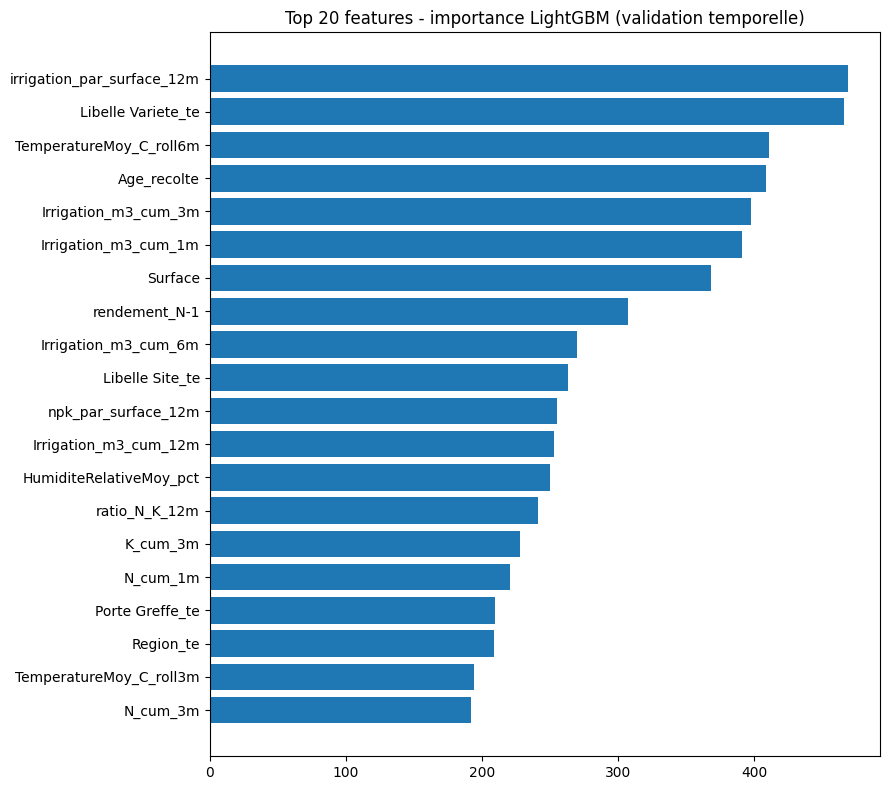

,feature,importance
25,irrigation_par_surface_12m,469
40,Libelle Variete_te,466
33,TemperatureMoy_C_roll6m,411
1,Age_recolte,409
7,Irrigation_m3_cum_3m,398
6,Irrigation_m3_cum_1m,391
0,Surface,368
35,rendement_N-1,307
8,Irrigation_m3_cum_6m,270
42,Libelle Site_te,263


In [8]:

importances = pd.DataFrame({
    "feature": X_train.columns,
    "importance": model_time.feature_importances_,
}).sort_values("importance", ascending=False)

plt.figure(figsize=(9, 8))
plt.barh(importances["feature"][:20][::-1], importances["importance"][:20][::-1])
plt.title("Top 20 features - importance LightGBM (validation temporelle)")
plt.tight_layout()
plt.show()

importances.head(15)


## 7. Ré-entraînement final sur tout le train, prédiction du test et soumission

In [9]:

final_model = lgb.LGBMRegressor(**lgb_params)
final_model.fit(X_train, y_train)

test_pred_log = final_model.predict(X_test)
test_pred_kg = np.clip(np.expm1(test_pred_log), 0, None)

submission = pd.DataFrame({
    "id": meta_test["id"],
    "Tonnage (Kg)": test_pred_kg,
})
print(submission.describe())
submission.head()


               id   Tonnage (Kg)
count   411.00000     411.000000
mean   1834.00000   20854.871479
std     118.78973   31939.061908
min    1629.00000      34.855610
25%    1731.50000    3131.399000
50%    1834.00000   11673.432325
75%    1936.50000   24603.516856
max    2039.00000  333409.132869


,id,Tonnage (Kg)
0,1629,19002.321064
1,1630,45042.826913
2,1631,84879.141689
3,1632,49275.977907
4,1633,73686.923385


In [10]:

sub_path = PROJECT_ROOT / "submission.csv"
submission.to_csv(sub_path, index=False)
print(f"Soumission sauvegardée : {sub_path}")

cold_start_share = meta_test["cold_start"].mean() if "cold_start" in meta_test.columns else None
if cold_start_share is not None:
    print(f"\nPart de lignes test en cold-start (parcelle jamais vue en train) : {cold_start_share:.1%}")
    print("-> à surveiller en priorité si l'erreur de soumission est plus élevée que prévu.")


Soumission sauvegardée : C:\Github_Projects\Competition_Kaggle\Kaggle_competition\submission.csv

Part de lignes test en cold-start (parcelle jamais vue en train) : 4.4%
-> à surveiller en priorité si l'erreur de soumission est plus élevée que prévu.
